In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from options_engine.models.binomial import crr_price
from options_engine.models.black_scholes import bsm_price

sns.set_theme(style="whitegrid")

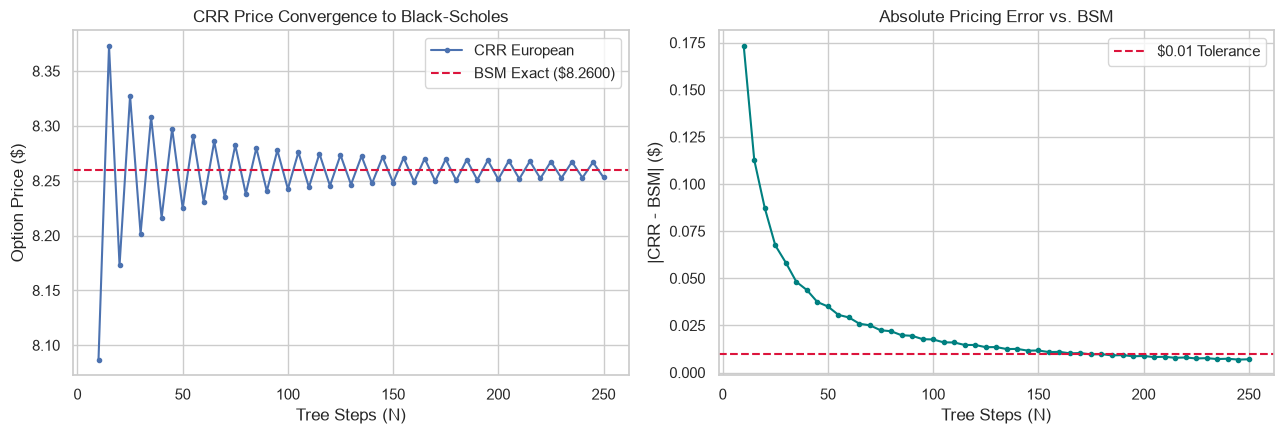

In [2]:
S, K, T, r, sigma = 100.0, 100.0, 0.5, 0.05, 0.25
bsm_ref = bsm_price(S, K, T, r, sigma, option_type="call")

steps = range(10, 255, 5)
crr_prices = [crr_price(S, K, T, r, sigma, N=n, option_type="call", exercise="european") for n in steps]
errors = [abs(p - bsm_ref) for p in crr_prices]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(steps, crr_prices, marker="o", ms=3, label="CRR European")
axes[0].axhline(bsm_ref, color="crimson", ls="--", label=f"BSM Exact (${bsm_ref:.4f})")
axes[0].set_title("CRR Price Convergence to Black-Scholes")
axes[0].set_xlabel("Tree Steps (N)")
axes[0].set_ylabel("Option Price ($)")
axes[0].legend()

axes[1].plot(steps, errors, color="teal", marker="o", ms=3)
axes[1].axhline(0.01, color="crimson", ls="--", label="$0.01 Tolerance")
axes[1].set_title("Absolute Pricing Error vs. BSM")
axes[1].set_xlabel("Tree Steps (N)")
axes[1].set_ylabel("|CRR - BSM| ($)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [3]:
proc_dir = Path("../data/processed")
latest_pq = sorted(proc_dir.glob("valuations_*.parquet"))[-1]
df = pd.read_parquet(latest_pq)
print(f"Loaded {len(df)} contracts from {latest_pq.name}")
df.head()

Loaded 353 contracts from valuations_20261121_081800.parquet


,ticker,expiration,option_type,strike,spot,T,moneyness,iv,market_mid,crr_american,crr_european,early_exercise_premium,pricing_error,abs_error,pct_error,delta,gamma,theta,vega,rho
0,SPY,2026-11-23,call,620.0,689.809998,0.006815,0.898798,1.014165,73.465,72.577671,72.577671,0.0,-0.887329,0.887329,0.012078,0.907070,0.002888,-1.998744,0.094370,0.037696
1,SPY,2026-11-23,call,625.0,689.809998,0.006815,0.906047,0.953492,68.395,67.553995,67.553995,0.0,-0.841005,0.841005,0.012296,0.902904,0.003169,-1.940725,0.104471,0.037843
2,SPY,2026-11-23,call,635.0,689.809998,0.006815,0.920543,0.869508,58.755,57.888785,57.888785,0.0,-0.866215,0.866215,0.014743,0.883898,0.003955,-2.011242,0.105313,0.037608
3,SPY,2026-11-23,call,640.0,689.809998,0.006815,0.927792,0.816896,53.815,52.964908,52.964908,0.0,-0.850092,0.850092,0.015797,0.875083,0.004432,-1.989933,0.124109,0.037529
4,SPY,2026-11-23,call,645.0,689.809998,0.006815,0.935040,0.766360,48.920,48.092491,48.092491,0.0,-0.827509,0.827509,0.016916,0.863849,0.005008,-1.979110,0.124590,0.037333


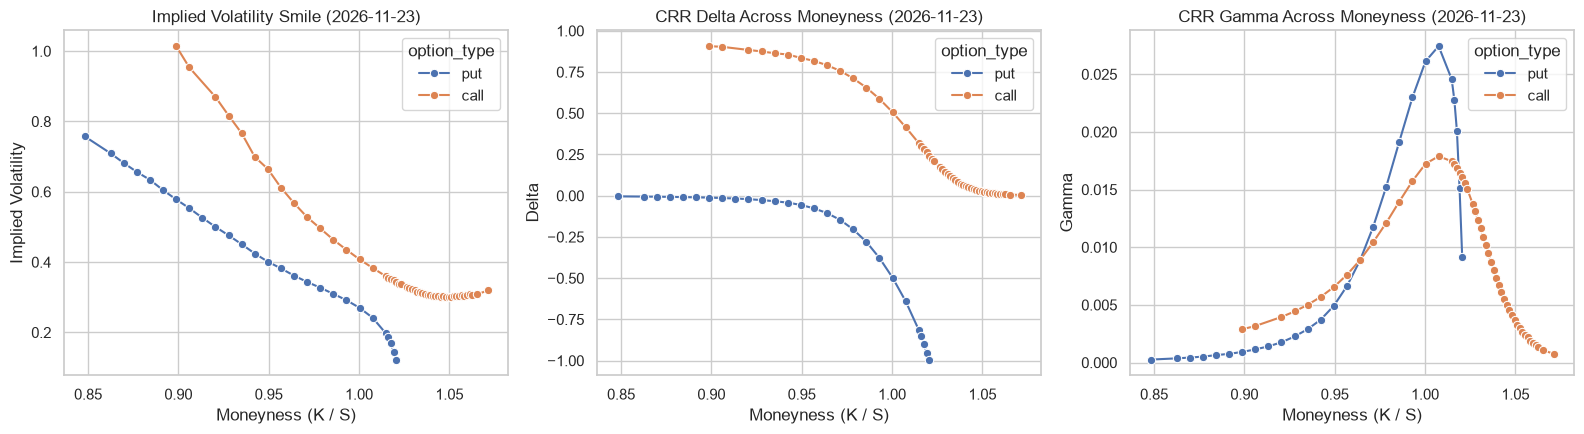

In [4]:
nearest_exp = df["expiration"].min()
sub = df[df["expiration"] == nearest_exp].sort_values("strike")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Implied Volatility Smile
sns.lineplot(data=sub, x="moneyness", y="iv", hue="option_type", marker="o", ax=axes[0])
axes[0].set_title(f"Implied Volatility Smile ({nearest_exp})")
axes[0].set_xlabel("Moneyness (K / S)")
axes[0].set_ylabel("Implied Volatility")

# 2. Delta Profile
sns.lineplot(data=sub, x="moneyness", y="delta", hue="option_type", marker="o", ax=axes[1])
axes[1].set_title(f"CRR Delta Across Moneyness ({nearest_exp})")
axes[1].set_xlabel("Moneyness (K / S)")
axes[1].set_ylabel("Delta")

# 3. Gamma Profile
sns.lineplot(data=sub, x="moneyness", y="gamma", hue="option_type", marker="o", ax=axes[2])
axes[2].set_title(f"CRR Gamma Across Moneyness ({nearest_exp})")
axes[2].set_xlabel("Moneyness (K / S)")
axes[2].set_ylabel("Gamma")

plt.tight_layout()
plt.show()